# VIS4AI · Notebook 03: Visualizations (with the support of AI)

Goal of this notebook: look at the same results as Notebook 02 (`run_4`), but made by the AI-aided pair
(see [`AI_USAGE_LOG.md`](../AI_USAGE_LOG.md)). Notebook 02 already covers the averages (accuracy, tokens, correlations),
so here we look at **single problems**, starting with the open question from the README:

> *Are the two models making mistakes in the same questions or different ones?*

### How to run
* **Colab:** `Runtime → Run all`. The results are read from Google Drive (`VIS4AI/results/<RUN>`).
* **Locally:** put the run folder in `data/` at the repo root (e.g. `data/run_4_2026-11-08_15-40/` or `data/run_4/`).

## 1. Setup and loading the results

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

RUN = "run_4_2026-11-08_15-40"   # the run analysed in Notebook 02

try:                               # on Colab: read from Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/VIS4AI/results") / RUN
except ImportError:                # locally: read from data/ in the repo
    data_dir = Path.cwd().parent / "data" if Path.cwd().name == "notebooks" else Path.cwd() / "data"
    RESULTS_DIR = next(p for p in [data_dir / RUN, data_dir / RUN.split("_2")[0]] if p.exists())

plt.rcParams["text.parse_math"] = False   # questions contain "$" signs

MODELS = {"r1-distill": "R1-Distill-1.5B", "qwen-math": "Qwen2.5-Math-1.5B"}   # file name -> short label
print("Reading results from:", RESULTS_DIR)

Reading results from: <repo>/data/run_4


In [2]:
def outcome(row):
    # Same categories as the comparison table in Notebook 01
    if not row["finished"]:
        return "cut off"
    if row["answer"] is None or pd.isna(row["answer"]):
        return "no answer"
    return "correct" if row["correct"] else "wrong"


results = []
for key, label in MODELS.items():
    df = pd.read_json(RESULTS_DIR / f"{key}.jsonl", lines=True, dtype={"gold": str, "answer": str})
    df["model"] = label
    df["outcome"] = df.apply(outcome, axis=1)
    results.append(df)
results = pd.concat(results, ignore_index=True)

# One row per problem, one column per model
outcomes = results.pivot(index="id", columns="model", values="outcome")[list(MODELS.values())]
answers  = results.pivot(index="id", columns="model", values="answer")[list(MODELS.values())]
problems = results.drop_duplicates("id").set_index("id")[["question", "gold"]]

results.groupby("model")["outcome"].value_counts().unstack(fill_value=0)

outcome,correct,cut off,wrong
model,,,
Qwen2.5-Math-1.5B,40,2,8
R1-Distill-1.5B,43,3,4


## 2. Do the two models fail on the same problems?

The table counts the problems by the outcome of **both** models at once (rows: R1-Distill, columns: Qwen2.5-Math).

In [3]:
r1, qwen = MODELS.values()
pd.crosstab(outcomes[r1], outcomes[qwen], margins=True, margins_name="total")

Qwen2.5-Math-1.5B,correct,cut off,wrong,total
R1-Distill-1.5B,,,,
correct,40,0,3,43
cut off,0,1,2,3
wrong,0,1,3,4
total,40,2,8,50


### Overview: every problem, both models
Each column is one problem, sorted into groups by what happened to the two models.
Colour shows the outcome and the symbol repeats it, so the plot can be read without colour too:
`✓` correct, `✗` wrong, `…` cut off at the token limit, `–` no answer.

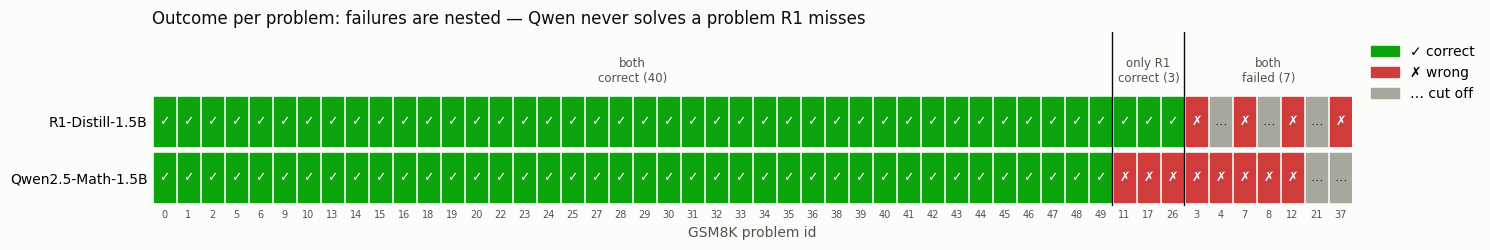

In [4]:
COLORS  = {"correct": "#0ca30c", "wrong": "#d03b3b", "cut off": "#a8a79e", "no answer": "#e1e0d9"}
SYMBOLS = {"correct": "✓", "wrong": "✗", "cut off": "…", "no answer": "–"}
INK, INK_MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"


def group(row):
    ok_r1, ok_qwen = row[r1] == "correct", row[qwen] == "correct"
    if ok_r1 and ok_qwen:
        return "both correct"
    if ok_r1:
        return f"only {r1} correct"
    if ok_qwen:
        return f"only {qwen} correct"
    return "both failed"


GROUP_ORDER = ["both correct", f"only {r1} correct", f"only {qwen} correct", "both failed"]
groups = outcomes.apply(group, axis=1)
order = sorted(outcomes.index, key=lambda i: (GROUP_ORDER.index(groups[i]), i))

fig, ax = plt.subplots(figsize=(15, 2.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for x, pid in enumerate(order):
    for y, model in enumerate(MODELS.values()):
        o = outcomes.loc[pid, model]
        ax.add_patch(plt.Rectangle((x + 0.06, y + 0.06), 0.88, 0.88, color=COLORS[o]))   # gap between cells
        ax.text(x + 0.5, y + 0.5, SYMBOLS[o], ha="center", va="center", fontsize=9,
                color=INK if o in ("cut off", "no answer") else "white")

# Group labels and separators above the grid
x = 0
for g in GROUP_ORDER:
    n = int((groups == g).sum())
    if n == 0:
        continue
    label = g.replace(r1, "R1").replace(qwen, "Qwen").replace(" correct", "\ncorrect").replace("both failed", "both\nfailed")
    ax.text(x + n / 2, -0.15, f"{label} ({n})", ha="center", va="bottom", fontsize=8.5, color=INK_MUTED)
    if x > 0:
        ax.axvline(x, color=INK, lw=1)
    x += n

ax.set_xlim(0, len(order))
ax.set_ylim(len(MODELS), -1.1)
ax.set_yticks([0.5, 1.5], list(MODELS.values()))
ax.set_xticks(np.arange(len(order)) + 0.5, order, fontsize=7, color=INK_MUTED)
ax.set_xlabel("GSM8K problem id", color=INK_MUTED)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[Patch(color=c, label=f"{SYMBOLS[o]} {o}") for o, c in COLORS.items()
                   if (outcomes == o).any().any()],
          loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False)
ax.set_title("Outcome per problem: failures are nested — Qwen never solves a problem R1 misses",
             loc="left", fontsize=12, color=INK)
plt.tight_layout()
plt.show()

### Zoom in: the problems where at least one model failed
Same colours, but now each cell shows the **answer the model gave**, next to the correct one.
Identical wrong answers from both models are marked with `=`.

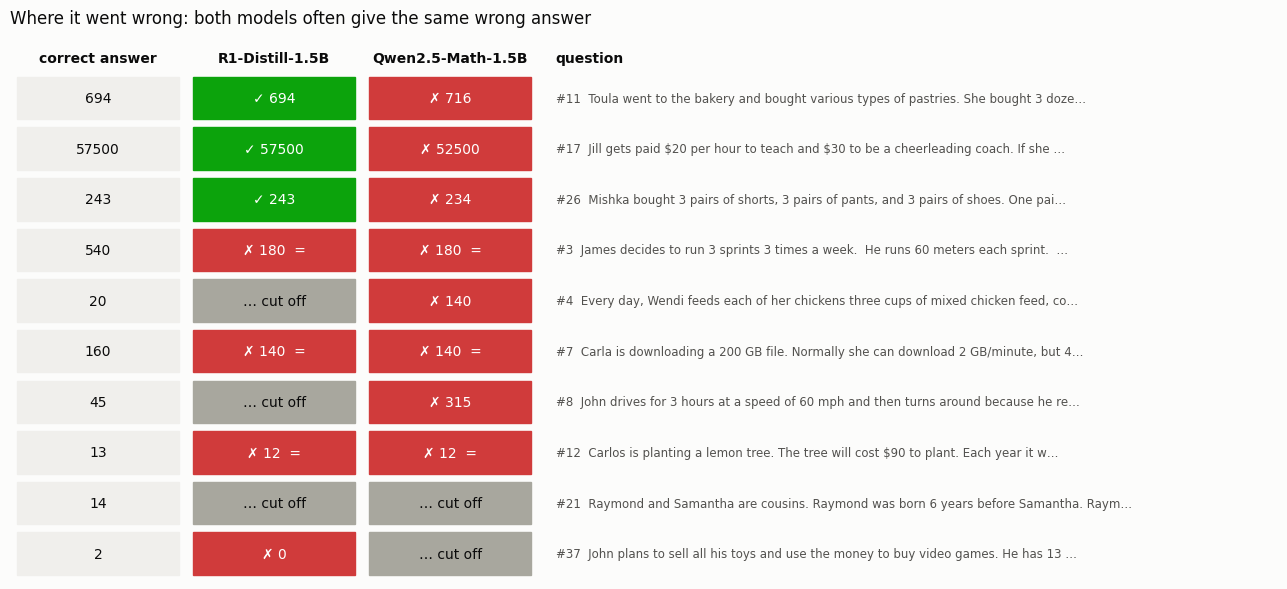

In [5]:
failed = [pid for pid in order if groups[pid] != "both correct"]

fig, ax = plt.subplots(figsize=(13, 0.48 * len(failed) + 1.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
columns = ["correct answer", *MODELS.values()]

for y, pid in enumerate(failed):
    a1, a2 = answers.loc[pid, r1], answers.loc[pid, qwen]
    same_wrong = outcomes.loc[pid, r1] == outcomes.loc[pid, qwen] == "wrong" and a1 == a2
    for x, col in enumerate(columns):
        if col == "correct answer":
            color, text, ink = "#f0efec", problems.loc[pid, "gold"], INK
        else:
            o = outcomes.loc[pid, col]
            ans = answers.loc[pid, col]
            text = f"{SYMBOLS[o]} {ans if o in ('correct', 'wrong') else o}" + ("  =" if same_wrong else "")
            color, ink = COLORS[o], (INK if o in ("cut off", "no answer") else "white")
        ax.add_patch(plt.Rectangle((x + 0.04, y + 0.08), 0.92, 0.84, color=color))
        ax.text(x + 0.5, y + 0.5, text, ha="center", va="center", fontsize=10, color=ink)
    question = problems.loc[pid, "question"]
    ax.text(len(columns) + 0.1, y + 0.5, f"#{pid}  " + (question[:80] + "…" if len(question) > 80 else question),
            va="center", fontsize=8.5, color=INK_MUTED)

ax.set_xlim(0, len(columns) + 4.2)
ax.set_ylim(len(failed), -0.6)
for x, col in enumerate(columns):
    ax.text(x + 0.5, -0.15, col, ha="center", va="bottom", fontsize=10, weight="bold", color=INK)
ax.text(len(columns) + 0.1, -0.15, "question", va="bottom", fontsize=10, weight="bold", color=INK)
ax.axis("off")
ax.set_title("Where it went wrong: both models often give the same wrong answer",
             loc="left", fontsize=12, color=INK, pad=14)
plt.tight_layout()
plt.show()

In [6]:
# Read one question in full (change the id to look at another one)
PROBLEM_ID = failed[0]
print(f"#{PROBLEM_ID}:", problems.loc[PROBLEM_ID, "question"])
print("\ncorrect:", problems.loc[PROBLEM_ID, "gold"], "|",
      " | ".join(f"{m}: {answers.loc[PROBLEM_ID, m]} ({outcomes.loc[PROBLEM_ID, m]})" for m in MODELS.values()))

#11: Toula went to the bakery and bought various types of pastries. She bought 3 dozen donuts which cost $68 per dozen, 2 dozen mini cupcakes which cost $80 per dozen, and 6 dozen mini cheesecakes for $55 per dozen. How much was the total cost?

correct: 694 | R1-Distill-1.5B: 694 (correct) | Qwen2.5-Math-1.5B: 716 (wrong)


### Observations (run_4)
*To be filled in by the team after looking at the plots.* Starting points from the AI:
* The failures are **nested**: there is no problem that Qwen2.5-Math solves and R1-Distill does not.
  R1 additionally solves 3 problems Qwen gets wrong.
* In 3 problems (#3, #7, #12) both models give the **same wrong answer**. R1-Distill was fine-tuned from Qwen2.5-Math,
  so a shared misreading of the question is a plausible explanation; check by reading those questions and outputs.
* Both fail in 7 of 50 problems. R1 fails by being **cut off** at 8192 tokens almost as often as by a wrong answer (3 vs 4),
  while Qwen's failures are mostly **wrong** answers (8 wrong, 2 cut off at 2048 tokens).